In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = "images"
EXPRESSIONS = ["neutral", "smiling", "surprised"]
VALID_EXT = (".jpg", ".jpeg", ".png")
TARGET_SIZE = (256, 256)  # every image resized to the same dimensions

In [2]:
def find_image(member_dir, expression):
    """Return the path for an expression, accepting .jpg/.jpeg/.png."""
    for ext in VALID_EXT:
        path = os.path.join(member_dir, expression + ext)
        if os.path.exists(path):
            return path
    return None


def discover_members(image_dir=IMAGE_DIR):
    """Scan images/ and report which members have all 3 expressions."""
    members = {}
    for name in sorted(os.listdir(image_dir)):
        member_dir = os.path.join(image_dir, name)
        if not os.path.isdir(member_dir):
            continue
        paths = {exp: find_image(member_dir, exp) for exp in EXPRESSIONS}
        missing = [exp for exp, p in paths.items() if p is None]
        if missing:
            print(f"⚠ {name}: missing {missing}")
        else:
            print(f"✓ {name}: all 3 expressions found")
        members[name] = {exp: p for exp, p in paths.items() if p}
    return members


members = discover_members()
print(f"\nTotal members found: {len(members)}")

✓ Anglebert: all 3 expressions found
✓ Mukasa: all 3 expressions found
✓ Nina: all 3 expressions found

Total members found: 3


In [3]:
def load_image(path, size=TARGET_SIZE):
    """Load an image as RGB and resize it so all images share one shape."""
    image = cv2.imread(path)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return cv2.resize(image, size, interpolation=cv2.INTER_AREA)


images = {
    member: {exp: load_image(path) for exp, path in paths.items()}
    for member, paths in members.items()
}

for member, exps in images.items():
    for exp, img in exps.items():
        print(f"{member:12s} {exp:10s} shape={img.shape} dtype={img.dtype}")

Anglebert    neutral    shape=(256, 256, 3) dtype=uint8
Anglebert    smiling    shape=(256, 256, 3) dtype=uint8
Anglebert    surprised  shape=(256, 256, 3) dtype=uint8
Mukasa       neutral    shape=(256, 256, 3) dtype=uint8
Mukasa       smiling    shape=(256, 256, 3) dtype=uint8
Mukasa       surprised  shape=(256, 256, 3) dtype=uint8
Nina         neutral    shape=(256, 256, 3) dtype=uint8
Nina         smiling    shape=(256, 256, 3) dtype=uint8
Nina         surprised  shape=(256, 256, 3) dtype=uint8


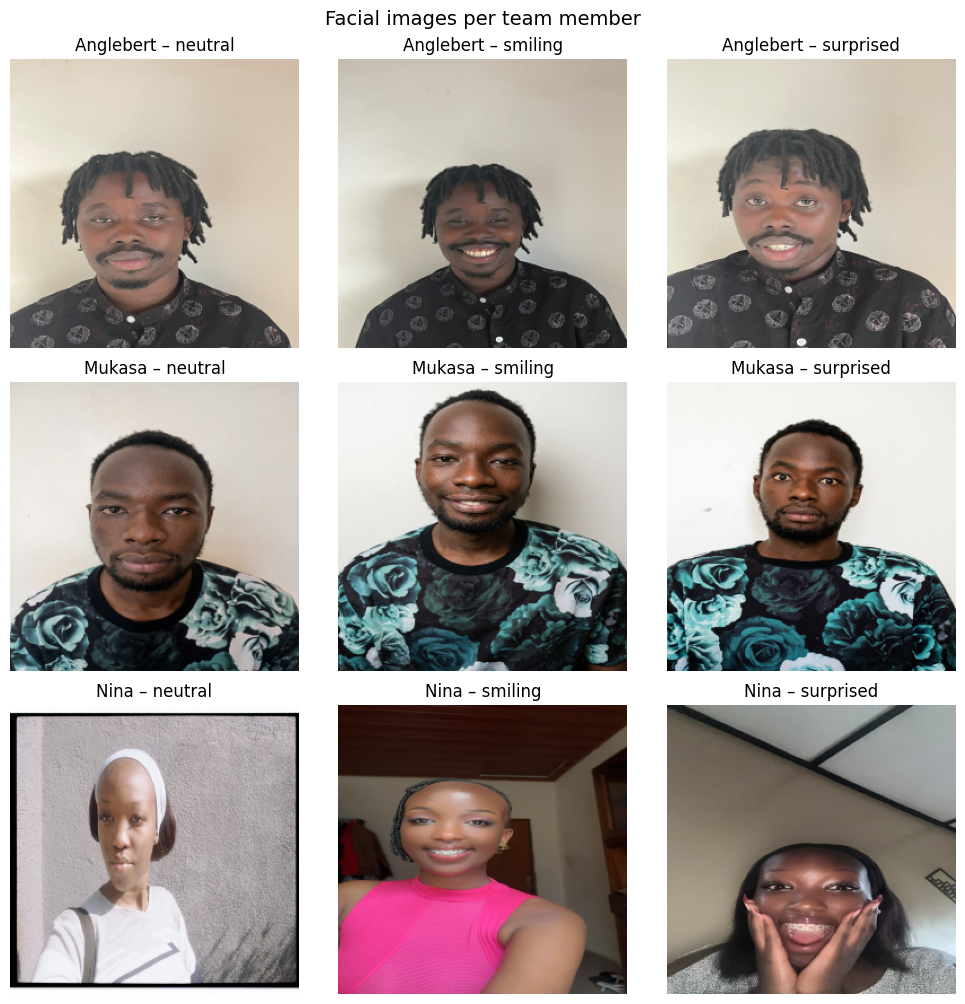

In [4]:
def display_member_grid(images):
    n = len(images)
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.4 * n), squeeze=False)
    for row, (member, exps) in enumerate(images.items()):
        for col, exp in enumerate(EXPRESSIONS):
            ax = axes[row][col]
            if exp in exps:
                ax.imshow(exps[exp])
            else:
                ax.text(0.5, 0.5, "missing", ha="center", va="center")
            ax.set_title(f"{member} – {exp}")
            ax.axis("off")
    plt.suptitle("Facial images per team member", fontsize=14)
    plt.tight_layout()
    plt.show()


display_member_grid(images)